# **Poner encabezados**

In [ ]:
import os
import pandas as pd

# Ruta de la carpeta
ruta = '/content/'

# Obtén la lista de archivos .csv
archivos_csv = [archivo for archivo in os.listdir(ruta) if archivo.lower().endswith('.csv')]

# Definición de encabezados
encabezados_con_extractor = ["Fecha", "Hora", "Temperatura 1", "Humedad 1", "Temperatura 2", "Humedad 2", "Temperatura 3", "Humedad 3", "Potencia", "Extractor"]
encabezados_sin_extractor = ["Fecha", "Hora", "Temperatura 1", "Humedad 1", "Temperatura 2", "Humedad 2", "Temperatura 3", "Humedad 3", "Potencia"]

print(f"Procesando {len(archivos_csv)} archivos...")

for archivo in archivos_csv:
    ruta_completa = os.path.join(ruta, archivo)

    try:
        # LEER: skiprows=1 salta la primera linea obligatoriamente como pediste.
        # header=None indica que lo que queda son puros datos crudos.
        df = pd.read_csv(ruta_completa, skiprows=1, header=None)

        # ASIGNAR ENCABEZADOS: Dependiendo del número de columnas detectadas
        num_columnas = len(df.columns)

        if num_columnas == 10:
            df.columns = encabezados_con_extractor
            # Guardamos sobrescribiendo el archivo original
            df.to_csv(ruta_completa, index=False)
            print(f" {archivo}: Formato corregido (10 columnas - Con Extractor).")

        elif num_columnas == 9:
            df.columns = encabezados_sin_extractor
            # Guardamos sobrescribiendo el archivo original
            df.to_csv(ruta_completa, index=False)
            print(f" {archivo}: Formato corregido (9 columnas - Sin Extractor).")

        else:
            print(f" {archivo}: Tiene {num_columnas} columnas. No coincide con los formatos esperados. Se omitió.")

    except Exception as e:
        print(f"Error procesando {archivo}: {e}")

print("Proceso de estandarización terminado.")

Procesando 2 archivos...
✓ 20250122.csv: Formato corregido (10 columnas - Con Extractor).
✓ 20250113.csv: Formato corregido (10 columnas - Con Extractor).
Proceso de estandarización terminado.


# **Borrar datos mayores a 100**

In [ ]:
import os
import pandas as pd
import numpy as np

# Ruta de la carpeta donde están los archivos .csv
ruta = '/content/'

# Obtener la lista de archivos .csv en la carpeta
archivos_csv = [archivo for archivo in os.listdir(ruta) if archivo.endswith('.csv') or archivo.endswith('.CSV')]

# Columnas a limpiar
columnas_filtrar = ["Temperatura 1", "Humedad 1", "Temperatura 2", "Humedad 2", "Temperatura 3", "Humedad 3"]

# Procesar cada archivo CSV
for archivo in archivos_csv:
    # Cargar el archivo CSV
    df = pd.read_csv(os.path.join(ruta, archivo))

    # Asegurar que las columnas existen antes de modificar
    columnas_presentes = [col for col in columnas_filtrar if col in df.columns]

    # Reemplazar valores mayores a 100 con el valor superior
    for col in columnas_presentes:
        df[col] = df[col].apply(lambda x: np.nan if x > 100 else x)  # Convertir valores > 100 en NaN
        df[col] = df[col].fillna(method='ffill')  # Rellenar con el valor anterior

    # Guarda el archivo modificado
    df.to_csv(os.path.join(ruta, archivo), index=False)

/tmp/ipython-input-969797600.py:25: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df[col] = df[col].fillna(method='ffill')  # Rellenar con el valor anterior
/tmp/ipython-input-969797600.py:25: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df[col] = df[col].fillna(method='ffill')  # Rellenar con el valor anterior


# **Rellenar valores**

In [ ]:
import os
import pandas as pd

# Ruta de la carpeta donde están los archivos .csv
ruta = '/content/'

# Obtén la lista de archivos .csv en la carpeta
archivos_csv = [archivo for archivo in os.listdir(ruta) if archivo.endswith('.csv') or archivo.endswith('.CSV')]

# Procesa cada archivo .csv
for archivo in archivos_csv:
    # Lee el archivo .csv con los encabezados especificados
    df = pd.read_csv(os.path.join(ruta, archivo), names=["Fecha", "Hora", "Temperatura 1", "Humedad 1", "Temperatura 2", "Humedad 2", "Temperatura 3", "Humedad 3", "Potencia", "Extractor"], header=0)

    # Iterar sobre las filas del DataFrame
    for n in range(1, len(df)):
        # Condiciones para Temperatura 2 y Humedad 2 (con OR)
        condicion_temp2 = pd.isnull(df.loc[n, "Temperatura 2"]) or df.loc[n, "Temperatura 2"] == "" or df.loc[n, "Temperatura 2"] < 5 or df.loc[n, "Temperatura 2"] > 90
        condicion_hum2 = pd.isnull(df.loc[n, "Humedad 2"]) or df.loc[n, "Humedad 2"] == "" or df.loc[n, "Humedad 2"] < 5 or df.loc[n, "Humedad 2"] > 101

        if condicion_temp2 or condicion_hum2:  # Si alguna de las dos condiciones es True
            diferencia_temp2 = df.loc[n - 1, "Temperatura 2"] - df.loc[n - 1, "Temperatura 1"]
            df.loc[n, "Temperatura 2"] = round(df.loc[n, "Temperatura 1"] + diferencia_temp2, 1)

            diferencia_hum2 = df.loc[n - 1, "Humedad 2"] - df.loc[n - 1, "Humedad 1"]
            df.loc[n, "Humedad 2"] = round(df.loc[n, "Humedad 1"] + diferencia_hum2, 1)


        # Condiciones para Temperatura 3 y Humedad 3 (con OR)
        condicion_temp3 = pd.isnull(df.loc[n, "Temperatura 3"]) or df.loc[n, "Temperatura 3"] == "" or df.loc[n, "Temperatura 3"] < 5 or df.loc[n, "Temperatura 3"] > 90
        condicion_hum3 = pd.isnull(df.loc[n, "Humedad 3"]) or df.loc[n, "Humedad 3"] == "" or df.loc[n, "Humedad 3"] < 5 or df.loc[n, "Humedad 3"] > 101

        if condicion_temp3 or condicion_hum3:  # Si alguna de las dos condiciones es True
            diferencia_temp3 = df.loc[n - 1, "Temperatura 3"] - df.loc[n - 1, "Temperatura 1"]
            df.loc[n, "Temperatura 3"] = round(df.loc[n, "Temperatura 1"] + diferencia_temp3, 1)

            diferencia_hum3 = df.loc[n - 1, "Humedad 3"] - df.loc[n - 1, "Humedad 1"]
            df.loc[n, "Humedad 3"] = round(df.loc[n, "Humedad 1"] + diferencia_hum3, 1)

    # Guarda el archivo modificado
    df.to_csv(os.path.join(ruta, archivo), index=False)

# **Graficar datos**

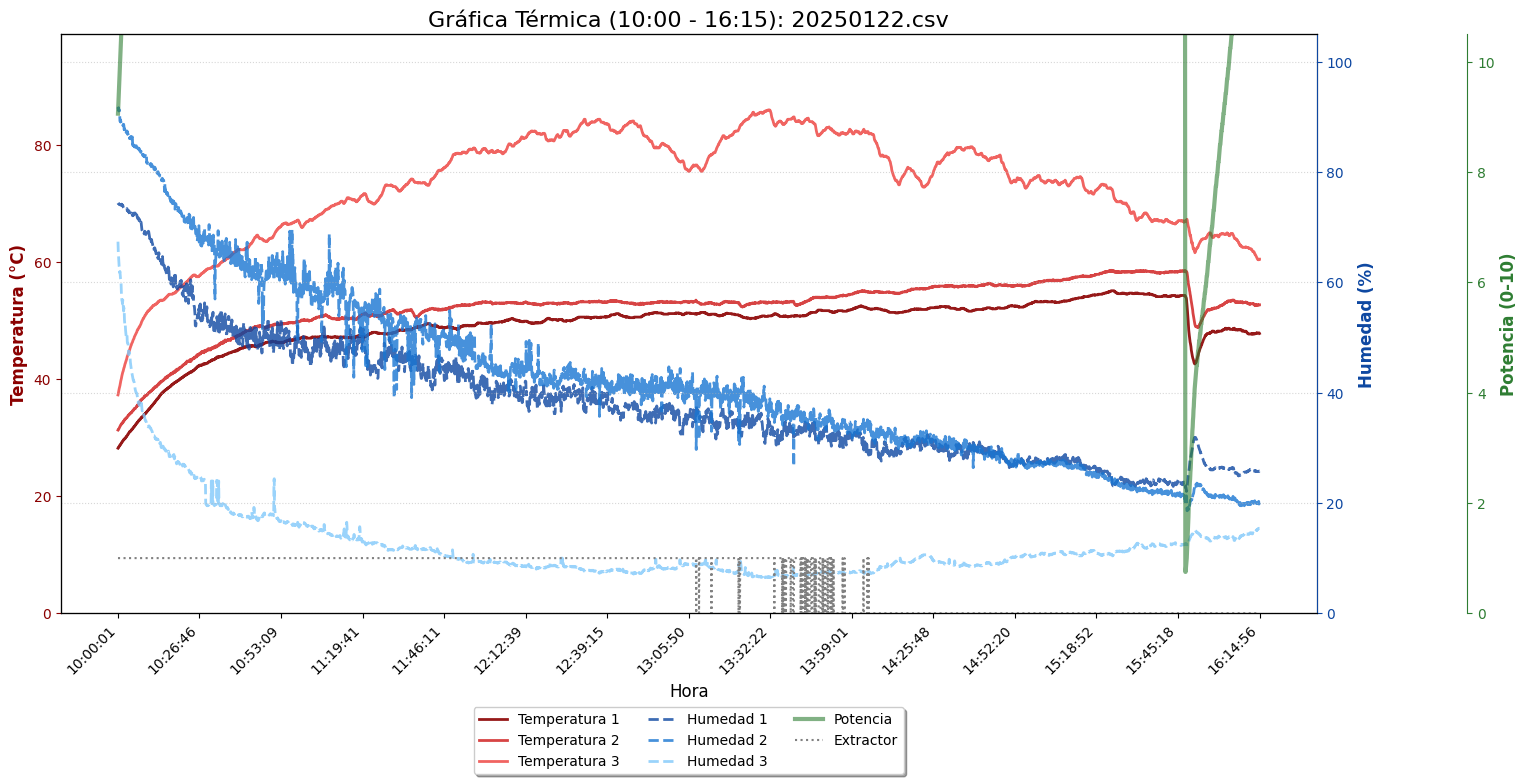

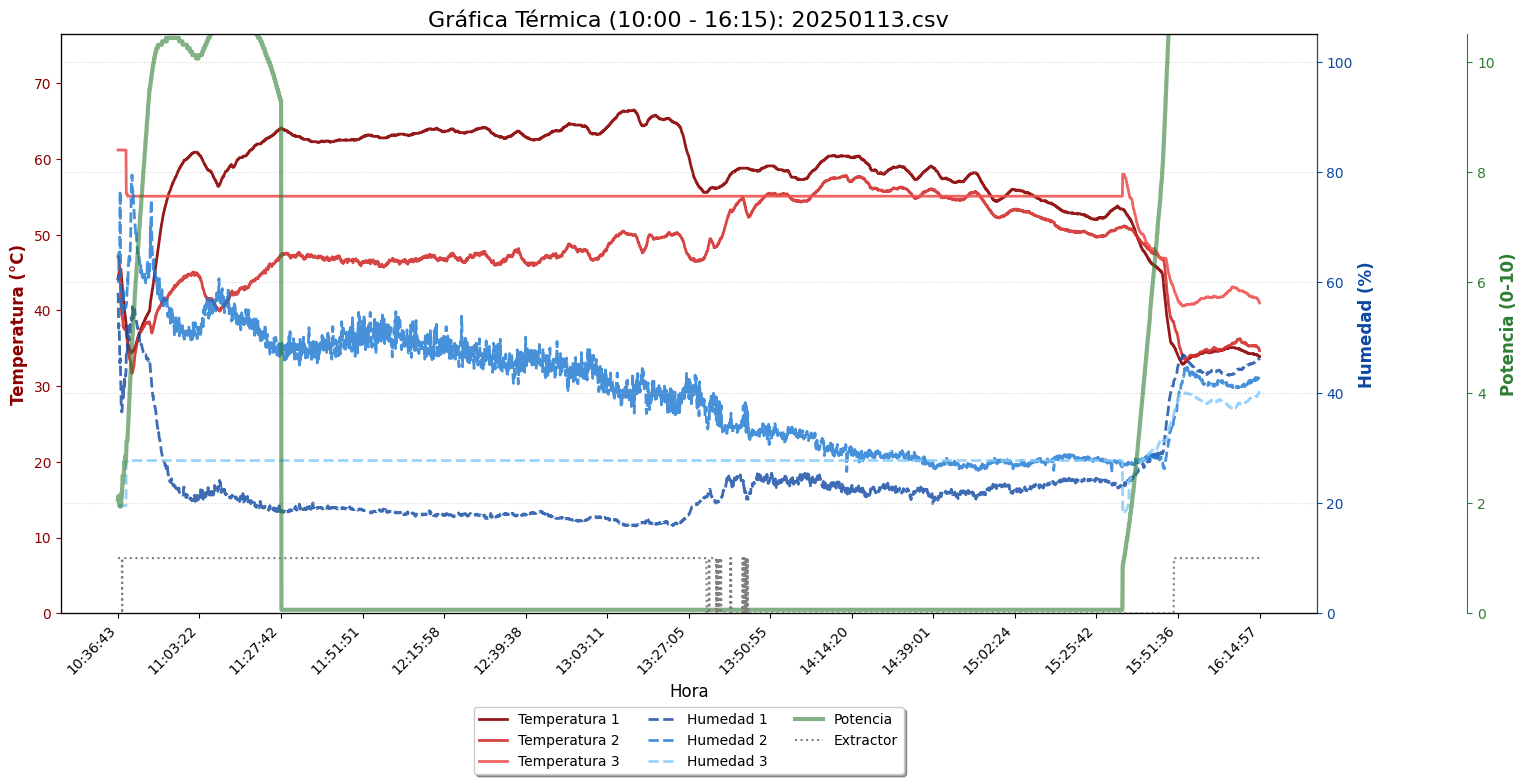

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Ruta de la carpeta
ruta = '/content/'
archivos_csv = [archivo for archivo in os.listdir(ruta) if archivo.lower().endswith('.csv')]

# --- DEFINICIÓN DE PALETAS DE COLOR (GRADIENTES) ---
colores_temp = ['#8B0000', '#D32F2F', '#EF5350']
colores_hum = ['#0D47A1', '#1976D2', '#81c9fa']

for archivo in archivos_csv:
    try:
        df = pd.read_csv(os.path.join(ruta, archivo))

        # --- LIMPIEZA Y FILTRO DE HORA ---
        # 1. Aseguramos el formato
        df['Hora'] = pd.to_datetime(df['Hora'], format='%H:%M:%S', errors='coerce').dt.strftime('%H:%M:%S')
        df = df.dropna(subset=['Hora'])

        # 2. FILTRO DE TIEMPO (10:00:00 a 16:15:00)
        # Como el formato es 24h estandar, podemos comparar strings directamente
        df = df[(df['Hora'] >= '10:00:00') & (df['Hora'] <= '16:15:00')]

        # Validación: Si el filtro borró todo (ej. archivo de noche), saltamos
        if df.empty:
            print(f"Saltando {archivo}: No tiene datos entre 10:00 y 16:15.")
            continue

        # --- LÓGICA DE POTENCIA ---
        df['Potencia'] = pd.to_numeric(df['Potencia'], errors='coerce').fillna(0)
        max_pot = df['Potencia'].max()
        base_escala = 160 if max_pot > 150 else 150
        df['Potencia Escala'] = (df['Potencia'] / base_escala) * 10

        if 'Extractor' in df.columns:
            df['Extractor'] = pd.to_numeric(df['Extractor'], errors='coerce').fillna(0)

        # --- CONFIGURACIÓN DE EJES ---
        fig, ax_temp = plt.subplots(figsize=(15, 8))
        fig.subplots_adjust(right=0.75)

        ax_hum = ax_temp.twinx()
        ax_pow = ax_temp.twinx()
        ax_pow.spines["right"].set_position(("axes", 1.12))

        lineas_temp = []
        lineas_hum = []

        # --- GRAFICAR DATOS ---

        # 1. TEMPERATURAS (Cálidos - Sólida)
        lista_temps = [c for c in df.columns if 'Temperatura' in c]
        for i, col in enumerate(lista_temps):
            color_actual = colores_temp[i % len(colores_temp)]
            l, = ax_temp.plot(df['Hora'], df[col],
                              color=color_actual,
                              linestyle='-',
                              linewidth=2,
                              alpha=0.9,
                              label=f'{col}')
            lineas_temp.append(l)

        # 2. HUMEDADES (Fríos - Guiones)
        lista_hums = [c for c in df.columns if 'Humedad' in c]
        for i, col in enumerate(lista_hums):
            color_actual = colores_hum[i % len(colores_hum)]
            l, = ax_hum.plot(df['Hora'], df[col],
                             color=color_actual,
                             linestyle='--',
                             linewidth=2,
                             alpha=0.8,
                             label=f'{col}')
            lineas_hum.append(l)

        # 3. POTENCIA (Verde Bosque)
        l_pot, = ax_pow.plot(df['Hora'], df['Potencia Escala'], color='#2E7D32', linewidth=3, alpha=0.6, label='Potencia')

        lineas_extra = [l_pot]
        if 'Extractor' in df.columns:
            l_ext, = ax_pow.plot(df['Hora'], df['Extractor'], color='gray', linestyle=':', label='Extractor')
            lineas_extra.append(l_ext)

        # --- ESTILOS VISUALES ---

        # Eje Izquierdo (TEMPERATURA)
        ax_temp.set_ylabel("Temperatura (°C)", color=colores_temp[0], fontweight='bold', fontsize=12)
        ax_temp.tick_params(axis='y', colors=colores_temp[0])
        max_t = df[lista_temps].max().max() if not df[lista_temps].empty else 50
        ax_temp.set_ylim(0, max_t * 1.15)

        # Eje Derecho 1 (HUMEDAD)
        ax_hum.set_ylabel("Humedad (%)", color=colores_hum[0], fontweight='bold', fontsize=12)
        ax_hum.tick_params(axis='y', colors=colores_hum[0])
        ax_hum.spines['right'].set_color(colores_hum[0])
        ax_hum.set_ylim(0, 105)

        # Eje Derecho 2 (POTENCIA)
        ax_pow.set_ylabel("Potencia (0-10)", color='#2E7D32', fontweight='bold', fontsize=12)
        ax_pow.tick_params(axis='y', colors='#2E7D32')
        ax_pow.spines['right'].set_color('#2E7D32')
        ax_pow.set_ylim(0, 10.5)

        ax_temp.set_xlabel("Hora", fontsize=12)
        plt.title(f'Gráfica Térmica (10:00 - 16:15): {archivo}', fontsize=16)

        # --- LEYENDA ---
        todas_lineas = lineas_temp + lineas_hum + lineas_extra
        labs = [l.get_label() for l in todas_lineas]

        ax_temp.legend(todas_lineas, labs, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True, fancybox=True, shadow=True)

        # Ticks X
        num_ticks = 15
        if len(df) > num_ticks:
            indices = np.linspace(0, len(df) - 1, num_ticks, dtype=int)
            ax_temp.set_xticks(df['Hora'].iloc[indices])
            ax_temp.set_xticklabels(df['Hora'].iloc[indices], rotation=45, ha='right')
        else:
            ax_temp.tick_params(axis='x', rotation=45)

        plt.grid(True, linestyle=':', alpha=0.5)
        plt.tight_layout()
        plt.savefig(archivo.split('.')[0] + '_grafico_filtrado.png', bbox_inches='tight')
        plt.show()

    except Exception as e:
        print(f"Error procesando {archivo}: {e}")

# **Descargar datos**

In [ ]:
import os
import shutil
from google.colab import files

# Obtiene la lista de archivos en la carpeta actual de Colab
archivos_en_carpeta = os.listdir('/content/')

# Filtra la lista de archivos para incluir tanto ".csv" como ".CSV" y ".png"
archivos_csv = [archivo for archivo in archivos_en_carpeta if archivo.lower().endswith(('.csv', '.CSV'))]
archivos_png = [archivo for archivo in archivos_en_carpeta if archivo.lower().endswith('.png')]

# Verifica si hay archivos .csv o .CSV antes de comprimirlos y descargarlos
if archivos_csv or archivos_png:
    # Crear un directorio temporal
    temp_dir = '/content/temp_dir'
    os.makedirs(temp_dir, exist_ok=True)

    # Copiar archivos CSV al directorio temporal
    for archivo in archivos_csv:
        shutil.copy(archivo, os.path.join(temp_dir, archivo))

    # Copiar archivos PNG al directorio temporal
    for archivo in archivos_png:
        shutil.copy(archivo, os.path.join(temp_dir, archivo))

    # Comprime los archivos en el directorio temporal en un archivo ZIP
    shutil.make_archive("/content/archivos_csv", 'zip', temp_dir)

    # Descarga el archivo ZIP
    files.download("/content/archivos_csv.zip")

    # Elimina el directorio temporal y su contenido
    shutil.rmtree(temp_dir)
else:
    print("No se encontraron archivos .csv o .CSV en la carpeta actual.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Promedio de voltaje y costo electrico**

In [ ]:
import pandas as pd
import os

# Obtén la lista de archivos CSV en /content
csv_files = [f for f in os.listdir('/content') if f.endswith('.csv')]

# Procesa cada archivo CSV
promedios_por_archivo = {}  # Diccionario para almacenar los promedios por archivo
all_potencias = []  # Lista para almacenar todas las potencias

for file in csv_files:
    # Lee el archivo CSV con encabezados existentes
    df = pd.read_csv(os.path.join('/content', file))

    # Accede a la columna "Potencia" (asumiendo que es la columna 9)
    potencias = df['Potencia']  # Asegúrate de que el nombre de la columna sea correcto

    # Escala los valores de la columna "Potencia"
    potencias_escaladas = potencias.apply(lambda x: (x - 1) / (175 - 1) * 120)

    # Calcula el promedio de potencia para este archivo
    promedio_archivo = potencias_escaladas.mean()
    promedios_por_archivo[file] = promedio_archivo

    # Agrega las potencias a la lista
    all_potencias.extend(potencias_escaladas.tolist())

# Calcula el promedio general de todos los archivos
promedio_general = sum(all_potencias) / len(all_potencias) if all_potencias else 0

# ---->  Aquí se agregan los nuevos cálculos  <----
# Crea un nuevo diccionario para almacenar los promedios modificados
promedios_modificados_por_archivo = {}

# Aplica las operaciones a los promedios de cada archivo
for file, promedio in promedios_por_archivo.items():
    promedio_modificado = (promedio * 2.08) / 1000 * 6
    promedios_modificados_por_archivo[file] = promedio_modificado

# Aplica las operaciones al promedio general
promedio_general_modificado = ((promedio_general * 2.08) / 1000) * 6

# Muestra los resultados originales
print("Promedio de potencia por archivo:")
for file, promedio in promedios_por_archivo.items():
    print(f"{file}: {promedio}")

print(f"\nPromedio general de potencia: {promedio_general}")

# Muestra los resultados modificados
print("\nPromedio de potencia modificado por archivo:")
for file, promedio_modificado in promedios_modificados_por_archivo.items():
    print(f"{file}: {promedio_modificado}")

print(f"\nPromedio general de potencia modificado: {promedio_general_modificado}")

Promedio de potencia por archivo:
20250115.csv: 29.929277865710286
20250114.csv: 77.37878787878788
20250116.csv: 54.35618119749914
20250113.csv: 16.97271326848291

Promedio general de potencia: 46.056583438970804

Promedio de potencia modificado por archivo:
20250115.csv: 0.37351738776406435
20250114.csv: 0.9656872727272727
20250116.csv: 0.6783651413447893
20250113.csv: 0.21181946159066672

Promedio general de potencia modificado: 0.5747861613183557
